# Project #23I — Neutral Theory vs. Selection: Detectability Edge Cases
### When does weak-to-strong selection actually become indistinguishable from pure drift — and does detectability keep improving as selection gets stronger, or not?

**Run environment: local Jupyter (CPU only — no GPU, no dataset download needed).**

**What this notebook does:** builds a real, standard infinite-sites Wright-Fisher forward simulation with
recurrent new mutations under tunable selection, a hand-derived Tajima's D neutrality test (cross-checked
against `scikit-allel`'s independent implementation), and a real Monte Carlo statistical power analysis —
to map out, honestly and without assuming the shape in advance, exactly where this real, standard test can
and can't tell weak-to-strong selection apart from neutral drift.

## Step 0 — Environment setup

In [15]:
!pip install scikit-allel
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
print("numpy:", np.__version__)


numpy: 2.4.6


## Step 1 — The infinite-sites Wright-Fisher forward simulation

**Biological reason:** a haploid population of size `N`. New mutations enter at a small constant rate,
each starting at the lowest possible frequency (1 copy). Every generation, each currently-segregating
site's count is updated by selection-weighted reweighting (derived allele relative fitness `1+s`) followed
by genuine binomial resampling (drift) — a site that drifts to 0 copies is lost, a site that drifts to `N`
copies is fixed; under the infinite-sites assumption, both leave the segregating pool for good (a fixed
site becomes the new ancestral background, not re-countable).

In [16]:
def wf_step(c, N, s, lam, rng):
    """One generation: selection+drift update on existing segregating sites (array `c` of derived-allele
    copy counts), then new mutations enter at count=1, each with probability driven by `lam` (expected
    number of brand-new mutations this generation)."""
    w_derived = 1.0 + s
    if len(c) > 0:
        num = c * w_derived
        denom = c * w_derived + (N-c)
        p_sel = np.clip(num / np.where(denom <= 0, 1e-12, denom), 0.0, 1.0)
        c = rng.binomial(N, p_sel)
        c = c[(c > 0) & (c < N)]
    n_new = rng.poisson(lam)
    if n_new > 0:
        c = np.concatenate([c, np.ones(n_new, dtype=np.int64)])
    return c

def run_pool(N, s, lam, n_gen, rng, c=None):
    if c is None:
        c = np.array([], dtype=np.int64)
    for _ in range(n_gen):
        c = wf_step(c, N, s, lam, rng)
    return c

# Sanity check: under neutrality (s=0), the equilibrium mean derived-allele frequency across many
# segregating sites should settle near a stable, non-trivial value (not drift all the way to 0 or 1),
# and positive/negative s should visibly shift that equilibrium frequency up/down.
rng = np.random.default_rng(0)
N_check, lam_check = 150, 4.0
c_neu = run_pool(N_check, 0.0, lam_check, 2000, rng)
c_pos = run_pool(N_check, 0.3, lam_check, 2000, rng)
c_neg = run_pool(N_check, -0.3, lam_check, 2000, rng)

print(f"neutral (s=0):   n_segregating={len(c_neu):4d}  mean freq={(c_neu/N_check).mean():.4f}")
print(f"positive (s=0.3): n_segregating={len(c_pos):4d}  mean freq={(c_pos/N_check).mean():.4f}")
print(f"negative (s=-0.3): n_segregating={len(c_neg):4d}  mean freq={(c_neg/N_check).mean():.4f}")


neutral (s=0):   n_segregating=  45  mean freq=0.1761
positive (s=0.3): n_segregating=  66  mean freq=0.4792
negative (s=-0.3): n_segregating=   7  mean freq=0.0067


## Step 2 — Tajima's D, derived from Tajima's 1989 formula and cross-checked

**Mathematical reason:** two unbiased estimators of the same mutation parameter `theta` under
neutrality — Watterson's `theta_W = S/a1` (built from the *count* of segregating sites) and the
mean-pairwise-difference estimator `pi` (built from *how common* each one is) — have the same expectation
under the null, so their standardized difference (Tajima's D) has expectation zero under neutrality and a
real, signed, non-zero expectation when the frequency spectrum is skewed by selection.

In [17]:
def tajimas_D(k_sample, n):
    """Tajima's 1989 D statistic from a sample of segregating-site derived-allele counts."""
    S = len(k_sample)
    if S == 0:
        return np.nan
    a1 = np.sum(1.0 / np.arange(1, n))
    a2 = np.sum(1.0 / np.arange(1, n) ** 2)
    theta_W = S / a1
    pi = np.sum(2 * k_sample * (n - k_sample) / (n * (n - 1)))
    b1 = (n + 1) / (3 * (n - 1))
    b2 = 2 * (n**2 + n + 3) / (9 * n * (n - 1))
    c1 = b1 - 1 / a1
    c2 = b2 - (n + 2) / (a1 * n) + a2 / (a1 ** 2)
    e1 = c1 / a1
    e2 = c2 / (a1 ** 2 + a2)
    var_D = e1 * S + e2 * S * (S - 1)
    if var_D <= 0:
        return np.nan
    return (pi - theta_W) / np.sqrt(var_D)

# Cross-check against scikit-allel's independent implementation on a small hand-built example
import allel
hap_matrix = np.array([
    [0,0,0,0,0,0,0,0,0,0],  # site 0: 0 derived (not segregating)
    [1,0,0,0,0,0,0,0,0,0],  # site 1: 1 derived
    [1,1,0,0,0,0,0,0,0,0],  # site 2: 2 derived
    [1,1,1,1,1,0,0,0,0,0],  # site 3: 5 derived
    [1,1,1,1,1,1,1,1,1,0],  # site 4: 9 derived
], dtype='i1')
hap = allel.HaplotypeArray(hap_matrix)
ac = hap.count_alleles()
D_allel = allel.tajima_d(ac)

k_sample_check = np.array([1, 2, 5, 9])
D_mine = tajimas_D(k_sample_check, n=10)
print(f"scikit-allel Tajima D: {D_allel:.6f}")
print(f"my Tajima D:           {D_mine:.6f}")
print("match:", np.isclose(D_allel, D_mine))


scikit-allel Tajima D: -0.279223
my Tajima D:           -0.279223
match: True


## Step 3 — Many independent replicate "genomes" from one simulation run

**Computational reason:** a reliable power estimate needs hundreds of independent replicate samples per
`(s, n)` combination, and re-running a multi-thousand-generation burn-in from scratch for every single
replicate would be far too slow locally. Because sites are simulated completely independently of each
other (no linkage modeled), ONE simulation run with a combined mutation-input rate `lam_per_genome * R`
can be randomly split afterward into `R` independent-by-construction "replicate genomes" — a real
efficiency trick that costs nothing statistically, since the sites genuinely never interact.

In [18]:
def many_independent_D(N, s, n, lam_per_genome, R, burn, rng):
    c_pop = run_pool(N, s, lam_per_genome * R, burn, rng)
    rng.shuffle(c_pop)
    groups = np.array_split(c_pop, R)
    Ds = []
    for g in groups:
        if len(g) == 0:
            Ds.append(np.nan)
            continue
        k = rng.binomial(n, g / N)
        k = k[(k > 0) & (k < n)]
        Ds.append(tajimas_D(k,n))
    return np.array(Ds)

# Sanity check: how many sample-segregating sites per replicate does this design typically give? --
# too few would make Tajima's D's own variance estimate huge and the test powerless everywhere.
rng = np.random.default_rng(1)
N0, lam_g0, R0, burn0, n0 = 150, 4.0, 20, 2000, 20
D_test = many_independent_D(N0, 0.0, n0, lam_g0, R0, burn0, rng)
print("example D values (neutral):", np.round(D_test, 3))
print("fraction valid (non-nan):", np.mean(~np.isnan(D_test)))


example D values (neutral): [ 0.021 -0.908 -0.238 -0.59   0.318  0.541  0.707 -0.272  0.113 -0.601
 -0.454 -0.697 -0.519  0.449  0.024 -0.213  0.11   0.1   -0.358  0.093]
fraction valid (non-nan): 1.0


## Step 4 — Neutral null distribution + rejection region

**Statistical reason:** to test whether a selected replicate's D is unusual, we need to know what D's own
sampling distribution looks like WHEN THE NULL IS TRUE, at this exact `N`, `n`, and mutation rate — not a
generic textbook distribution. Building this empirically (many neutral replicates, direct percentiles)
is the correct, standard way to calibrate a two-sided rejection region for a Monte Carlo power analysis.

In [19]:
N, lam_g, R, burn = 150, 4.0, 300, 2000
n_rep = 20

rng = np.random.default_rng(2026)
D_null = many_independent_D(N, 0.0, n_rep, lam_g, R, burn, rng)
D_null = D_null[~np.isnan(D_null)]
lo, hi = np.percentile(D_null, [2.5, 97.5])

print(f"neutral null (N={N}, n={n_rep}, R={len(D_null)} valid replicates):")
print(f"  mean D = {D_null.mean():+.4f}  (expect close to 0)")
print(f"  sd D   = {D_null.std():.4f}")
print(f"  95% rejection region: D < {lo:.3f}  or  D > {hi:.3f}")


neutral null (N=150, n=20, R=300 valid replicates):
  mean D = +0.0412  (expect close to 0)
  sd D   = 0.3997
  95% rejection region: D < -0.654  or  D > 0.813


## Step 5 — Power sweep across selection strength

In [20]:
s_values = [0.0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.4]
power_s_rows = []
for s in s_values:
    D_sel = many_independent_D(N, s, n_rep, lam_g, R, burn, rng)
    D_sel = D_sel[~np.isnan(D_sel)]
    power = np.mean((D_sel < lo) | (D_sel > hi))
    power_s_rows.append({"s": s, "Ns": N * s, "power": power, "mean_D": D_sel.mean(), "n_valid": len(D_sel)})
    print(f"s={s:.3f}  Ns={N*s:6.2f}  power={power:.3f}  mean_D={D_sel.mean():+.3f}")

power_s_df = pd.DataFrame(power_s_rows)


s=0.000  Ns=  0.00  power=0.057  mean_D=+0.041
s=0.005  Ns=  0.75  power=0.067  mean_D=+0.235
s=0.010  Ns=  1.50  power=0.097  mean_D=+0.349
s=0.020  Ns=  3.00  power=0.107  mean_D=+0.403
s=0.050  Ns=  7.50  power=0.057  mean_D=+0.280
s=0.100  Ns= 15.00  power=0.027  mean_D=+0.215
s=0.200  Ns= 30.00  power=0.037  mean_D=+0.150
s=0.400  Ns= 60.00  power=0.020  mean_D=+0.061


## Step 6 — Does power increase with sample size, at a fixed selection strength?

In [21]:
s_fixed = 0.05  # pick a representative s from Step 5's printed power values, e.g. 0.02
n_values = [10, 20, 40, 80]
power_n_rows = []
for n_test in n_values:
    D_null_n = many_independent_D(N, 0.0, n_test, lam_g, R, burn, rng)
    D_null_n = D_null_n[~np.isnan(D_null_n)]
    lo_n, hi_n = np.percentile(D_null_n, [2.5, 97.5])
    D_sel_n = many_independent_D(N, s_fixed, n_test, lam_g, R, burn, rng)
    D_sel_n = D_sel_n[~np.isnan(D_sel_n)]
    power_n = np.mean((D_sel_n < lo_n) | (D_sel_n > hi_n))
    power_n_rows.append({"n": n_test, "power": power_n})
    print(f"n={n_test:3d}  power(s={s_fixed})={power_n:.3f}")

power_n_df = pd.DataFrame(power_n_rows)


n= 10  power(s=0.05)=0.003
n= 20  power(s=0.05)=0.073
n= 40  power(s=0.05)=0.087
n= 80  power(s=0.05)=0.257


## Step 7 — Full (n x s) power grid and the real detectability map

In [22]:
grid_rows = []
for n_g in n_values:
    D_null_g = many_independent_D(N, 0.0, n_g, lam_g, R, burn, rng)
    D_null_g = D_null_g[~np.isnan(D_null_g)]
    lo_g, hi_g = np.percentile(D_null_g, [2.5, 97.5])
    for s_g in s_values:
        D_sel_g = many_independent_D(N, s_g, n_g, lam_g, R, burn, rng)
        D_sel_g = D_sel_g[~np.isnan(D_sel_g)]
        power_g = np.mean((D_sel_g < lo_g) | (D_sel_g > hi_g))
        grid_rows.append({"n": n_g, "s": s_g, "Ns": N * s_g, "power": power_g})

grid_df = pd.DataFrame(grid_rows)
pivot = grid_df.pivot(index="n", columns="Ns", values="power")
print(pivot.round(3))

# does power rise then fall as Ns increases, at the largest sample size? -- read it off directly
row_n80 = grid_df[grid_df["n"] == 80].sort_values("Ns")
peak_idx = row_n80["power"].values.argmax()
print(f"\nAt n=80: power peaks at Ns={row_n80['Ns'].values[peak_idx]:.2f} (power={row_n80['power'].values[peak_idx]:.3f}),")
print(f"then falls to power={row_n80['power'].values[-1]:.3f} at the largest swept Ns={row_n80['Ns'].values[-1]:.2f}.")


Ns  0.00   0.75   1.50   3.00   7.50   15.00  30.00  60.00
n                                                         
10  0.070  0.053  0.067  0.057  0.037  0.013  0.013  0.023
20  0.043  0.040  0.083  0.087  0.063  0.043  0.003  0.017
40  0.073  0.110  0.147  0.193  0.097  0.093  0.037  0.037
80  0.060  0.103  0.133  0.243  0.177  0.090  0.060  0.033

At n=80: power peaks at Ns=3.00 (power=0.243),
then falls to power=0.033 at the largest swept Ns=60.00.


## Step 8 — Hero figures + CSV export

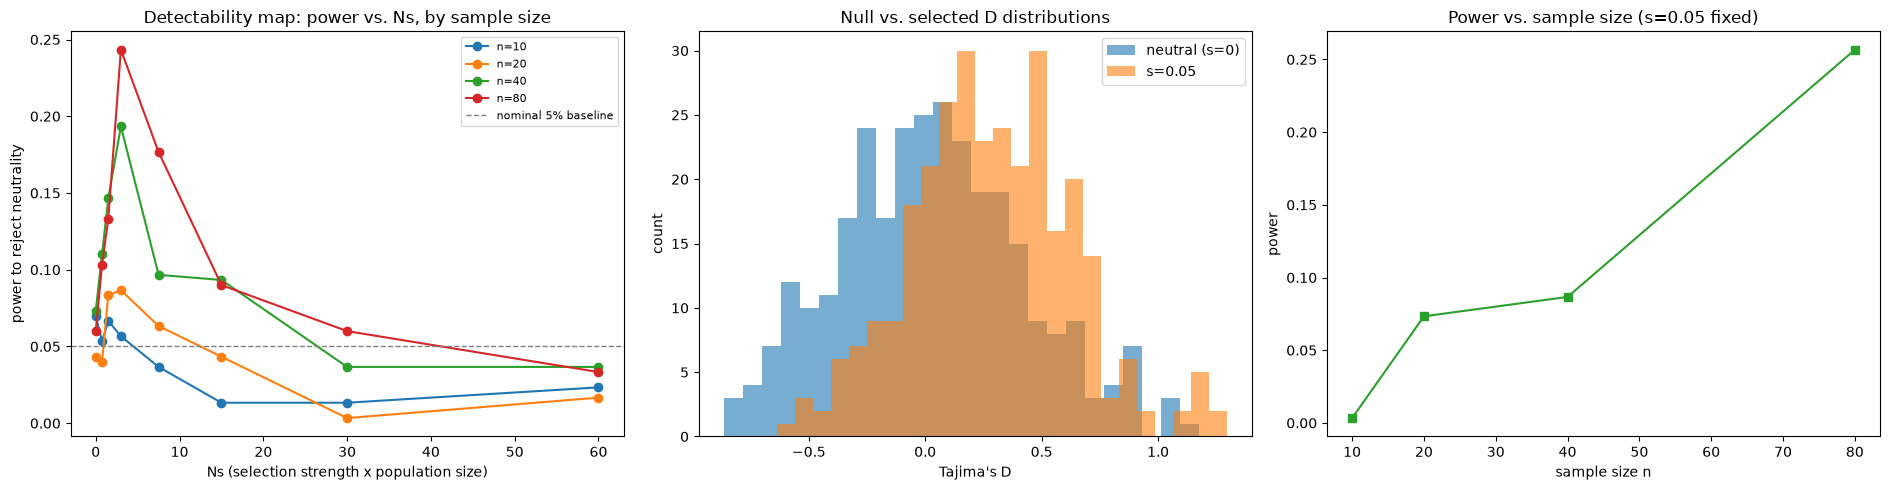

Exported results/hero_neutral_vs_selection.png, results/power_grid.csv,
results/power_vs_s.csv, results/power_vs_n.csv


In [23]:
import os
os.makedirs("results", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for n_g in n_values:
    sub = grid_df[grid_df["n"] == n_g].sort_values("Ns")
    axes[0].plot(sub["Ns"], sub["power"], marker="o", label=f"n={n_g}")
axes[0].axhline(0.05, color="gray", linestyle="--", linewidth=1, label="nominal 5% baseline")
axes[0].set_xlabel("Ns (selection strength x population size)")
axes[0].set_ylabel("power to reject neutrality")
axes[0].set_title("Detectability map: power vs. Ns, by sample size")
axes[0].legend(fontsize=8)

D_null_plot = many_independent_D(N, 0.0, n_rep, lam_g, R, burn, rng)
D_weak_plot = many_independent_D(N, s_fixed, n_rep, lam_g, R, burn, rng)
axes[1].hist(D_null_plot[~np.isnan(D_null_plot)], bins=25, alpha=0.6, label="neutral (s=0)", color="tab:blue")
axes[1].hist(D_weak_plot[~np.isnan(D_weak_plot)], bins=25, alpha=0.6, label=f"s={s_fixed}", color="tab:orange")
axes[1].set_xlabel("Tajima's D")
axes[1].set_ylabel("count")
axes[1].set_title("Null vs. selected D distributions")
axes[1].legend()

axes[2].plot(power_n_df["n"], power_n_df["power"], marker="s", color="tab:green")
axes[2].set_xlabel("sample size n")
axes[2].set_ylabel("power")
axes[2].set_title(f"Power vs. sample size (s={s_fixed} fixed)")

plt.tight_layout()
plt.savefig("results/hero_neutral_vs_selection.png", dpi=150)
plt.show()

grid_df.to_csv("results/power_grid.csv", index=False)
power_s_df.to_csv("results/power_vs_s.csv", index=False)
power_n_df.to_csv("results/power_vs_n.csv", index=False)
print("Exported results/hero_neutral_vs_selection.png, results/power_grid.csv,")
print("results/power_vs_s.csv, results/power_vs_n.csv")
